In [ ]:
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Define the file path
file_path_movies = '/content/drive/MyDrive/Colab Notebooks/movies.csv'

#Load the CSV file into a dataframe
movies = pd.read_csv(file_path_movies)

#Display the first few rows of dataframe
movies.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [ ]:
# Convert the single string of genres into a list
movies['genres'] = movies['genres'].apply(lambda x: x.split('|'))
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),"[Adventure, Animation, Children, Comedy, Fantasy]"
1,2,Jumanji (1995),"[Adventure, Children, Fantasy]"
2,3,Grumpier Old Men (1995),"[Comedy, Romance]"
3,4,Waiting to Exhale (1995),"[Comedy, Drama, Romance]"
4,5,Father of the Bride Part II (1995),[Comedy]


In [ ]:
# Import Counter from collections module, useful for counting hashable objects
from collections import Counter

# Access the genres column, iterate over each genre in the list and count how many times each genre appears across all movies
genres_counts = Counter(g for genres in movies['genres'] for g in genres)

# Print the unique genre labels
print(f"There are {len(genres_counts)} genre labels. \n")

#Display the genre counts
genres_counts



There are 20 genre labels. 



Counter({'Adventure': 1263,
         'Animation': 611,
         'Children': 664,
         'Comedy': 3756,
         'Fantasy': 779,
         'Romance': 1596,
         'Drama': 4361,
         'Action': 1828,
         'Crime': 1199,
         'Thriller': 1894,
         'Horror': 978,
         'Mystery': 573,
         'Sci-Fi': 980,
         'War': 382,
         'Musical': 334,
         'Documentary': 440,
         'IMAX': 158,
         'Western': 167,
         'Film-Noir': 87,
         '(no genres listed)': 34})

In [ ]:
# Remove movies with 'no genres listed
movies = movies[movies['genres'] != '(no genres listed)']

# Remove from genres_counts dictionary
del genres_counts['(no genres listed)']

#Print the unique numnber of genres labels
print(f'There are {len(genres_counts)} genres labels.')

# Update genres_counts after cleaning
genres_counts

There are 19 genres labels.


Counter({'Adventure': 1263,
         'Animation': 611,
         'Children': 664,
         'Comedy': 3756,
         'Fantasy': 779,
         'Romance': 1596,
         'Drama': 4361,
         'Action': 1828,
         'Crime': 1199,
         'Thriller': 1894,
         'Horror': 978,
         'Mystery': 573,
         'Sci-Fi': 980,
         'War': 382,
         'Musical': 334,
         'Documentary': 440,
         'IMAX': 158,
         'Western': 167,
         'Film-Noir': 87})

In [ ]:
# returns a list of tuples, where each tuple contains a genre and its count
print('The 5 most common genres: \n', genres_counts.most_common(5))

The 5 most common genres: 
 [('Drama', 4361), ('Comedy', 3756), ('Thriller', 1894), ('Action', 1828), ('Romance', 1596)]


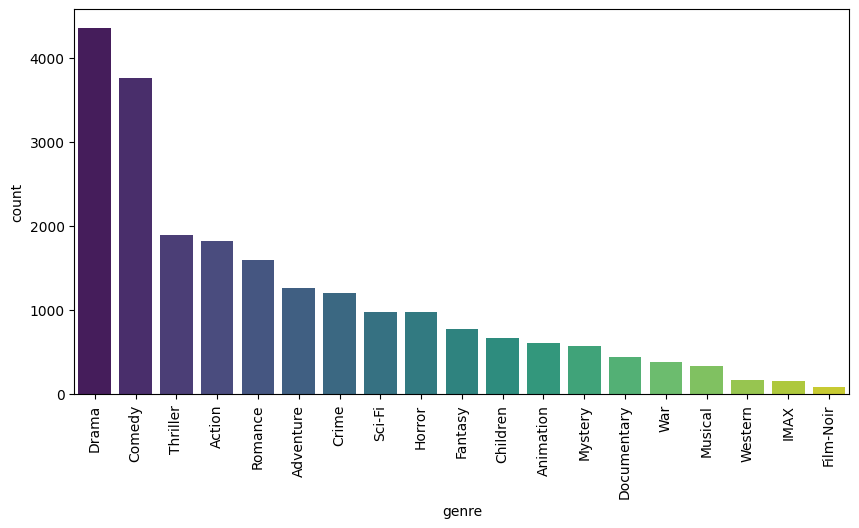

In [ ]:
# Converts the Counter object into a list, and reset the index of the DataFrame to default integer indices
# Rename the columns to 'genre' and 'count'
genres_counts_df = pd.DataFrame([genres_counts]).T.reset_index()
genres_counts_df.columns = ['genre', 'count']

# Sort the DataFrame in descending order based on the 'count' column
genres_counts_df = genres_counts_df.sort_values(by='count', ascending=False)

#Plotting
plt.figure(figsize=(10,5))
sns.barplot(x='genre', y='count', data=genres_counts_df, palette = 'viridis')
plt.xticks(rotation=90) # to display the xlabels vertically
plt.show()

In [ ]:
#module for regular expression operations
import re

# Function: extract_year_from_title
# Description: Extract the year from the movie title string and create a new column year
def extract_year_from_title(title):
  t = title.split(' ')
  year = None
  if re.search(r'\(\d+\)', t[-1]):
    year = t[-1].strip('()')
    year = int(year)
  return year


In [ ]:
# apply the above function and create a new column year
movies['year'] = movies['title'].apply(extract_year_from_title)
movies.head()

,movieId,title,genres,year
0,1,Toy Story (1995),"[Adventure, Animation, Children, Comedy, Fantasy]",1995.0
1,2,Jumanji (1995),"[Adventure, Children, Fantasy]",1995.0
2,3,Grumpier Old Men (1995),"[Comedy, Romance]",1995.0
3,4,Waiting to Exhale (1995),"[Comedy, Drama, Romance]",1995.0
4,5,Father of the Bride Part II (1995),[Comedy],1995.0


In [ ]:
x=1995
def round_down(year):
  return year - year % 10

round_down(x)

1990

In [ ]:
# Convert each year to the decade of that year
movies['year'] = movies['year'].apply(round_down)
movies.head()

,movieId,title,genres,year
0,1,Toy Story (1995),"[Adventure, Animation, Children, Comedy, Fantasy]",1990.0
1,2,Jumanji (1995),"[Adventure, Children, Fantasy]",1990.0
2,3,Grumpier Old Men (1995),"[Comedy, Romance]",1990.0
3,4,Waiting to Exhale (1995),"[Comedy, Drama, Romance]",1990.0
4,5,Father of the Bride Part II (1995),[Comedy],1990.0


In [ ]:
# Define the file path
file_path_ratings = '/content/drive/MyDrive/Colab Notebooks/ratings.csv'

# Load ratings
ratings = pd.read_csv(file_path_ratings)
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


**Updating the lab assignment with the evaluation of the recommender system**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity

# Split the data into training and testing sets
R_train, R_test = train_test_split(ratings, test_size=0.2, random_state=42)

# Remove movies with no genre
R_train = R_train[R_train['movieId'].isin(movies['movieId'])]
R_test = R_test[R_test['movieId'].isin(movies['movieId'])]

# Map movieId -> row index in movie_features
movieid_to_idx = dict(zip(movies['movieId'], movies.index))

# One-hot encode genres
genres = list(genres_counts.keys())
for g in genres:
    movies[g] = movies['genres'].transform(lambda x: int(g in x))

# One-hot encode decade
movie_decades = pd.get_dummies(movies['year'])

movie_features = pd.concat([movies[genres], movie_decades], axis=1)
cosine_sim = cosine_similarity(movie_features, movie_features)

# Predict rating using cosine similarity measures
def predict_ct_rating(user_id, movie_id, train_df):
  if movie_id not in movieid_to_idx:
    return np.nan
  target_idx = movieid_to_idx[movie_id]
  history = train_df[(train_df['userId'] == user_id)]

  if history.empty:
    return np.nan

  movie_idxs = history['movieId'].map(movieid_to_idx).values
  similar = cosine_sim[target_idx, movie_idxs]
  return (history['rating'].values.dot(similar)) / similar.sum()

In [ ]:
# Predict on the test set
test_subset = R_test.sample(n=300, random_state=42).copy()
test_subset['content_pred'] = test_subset.apply(
    lambda row: predict_ct_rating(row['userId'], row['movieId'], R_train), axis=1
)

content_eval = test_subset.dropna(subset=['content_pred'])

In [ ]:
from sklearn.metrics import mean_squared_error

content_mse = mean_squared_error(content_eval['rating'], content_eval['content_pred'])
content_rmse = np.sqrt(content_mse)

print(f"Content-Based — MSE: {content_mse:.4f}, RMSE: {content_rmse:.4f}")

Content-Based — MSE: 0.8556, RMSE: 0.9250
